# DBSCAN : construire les tournées de livraison

**Objectif :** regrouper les adresses de livraison du jour en tournées, à partir de leur position sur la carte.

Imports des bibliothèques utilisées dans tout le notebook.

In [1]:
import pandas as pd 
import matplotlib.pylab as plt
from sklearn.cluster import KMeans
from sklearn.neighbors import  NearestNeighbors
from sklearn.cluster import DBSCAN
import numpy as np 
from sklearn.preprocessing import StandardScaler


## 1. Chargement et description des données

In [2]:
df = pd.read_csv("livraisons_jour.csv")
print(df.head())
print("___________________________________________")
print(df.min())
print("___________________________________________")
print(df.max())
print("___________________________________________")
print(df.shape)



  adresse_id  est_ouest_km  nord_sud_km  nb_colis  poids_kg
0      A1294          2.91         6.61         2       3.0
1      A1162          7.52         4.27         1       4.2
2      A1093          5.62         2.13         8      31.2
3      A1112          6.95         2.36         5      19.9
4      A1107          6.65         2.21         3      11.7
___________________________________________
adresse_id      A1000
est_ouest_km     0.58
nord_sud_km      0.76
nb_colis            1
poids_kg          1.5
dtype: object
___________________________________________
adresse_id      A1355
est_ouest_km     9.42
nord_sud_km      9.43
nb_colis            9
poids_kg         39.0
dtype: object
___________________________________________
(356, 5)


**Question 1 : combien de lignes, combien de colonnes ?**

Le fichier contient **356 lignes** (une par adresse) et **5 colonnes**.

**Question 2 : minimums, maximums et unités des quatre colonnes numériques**

| Colonne | Min | Max | Unité |
|---|---|---|---|
| `est_ouest_km` | 0,58 | 9,42 | kilomètres |
| `nord_sud_km` | 0,76 | 9,43 | kilomètres |
| `nb_colis` | 1 | 9 | nombre de colis |
| `poids_kg` | 1,5 | 39,0 | kilogrammes |

Les deux positions sont dans la même unité (km) et ont à peu près la même étendue (environ 9 km). Le poids, lui, va jusqu'à 39 : ses écarts sont beaucoup plus grands que ceux des positions.

## 2. Nuage des adresses

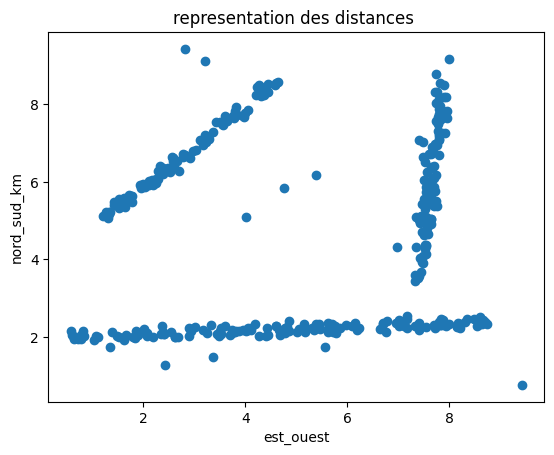

In [3]:
x = df["est_ouest_km"]
y = df["nord_sud_km"]

plt.scatter(x,y)
plt.xlabel("est_ouest")
plt.ylabel("nord_sud_km")
plt.title("representation des distances ")
plt.show()


**Question 3 : combien d'axes de livraison ? Y a-t-il des adresses à l'écart ?**

On distingue **3 axes de livraison** :
- un axe **en diagonale** vers le nord-est (de (1 ; 5) à environ (4,5 ; 8,5) km) ;
- un axe **vertical** vers le nord, autour de est-ouest ≈ 7,7 km ;
- un axe **horizontal** vers l'est, autour de nord-sud ≈ 2,2 km. Il a un petit trou vers 6,5 km.

**Environ 6 adresses** sont nettement à l'écart des axes (2 en haut à gauche, 3 au milieu de la carte, 1 tout en bas à droite), et quelques autres sont en limite, juste à côté d'un axe.

## 3. Essai avec K-means

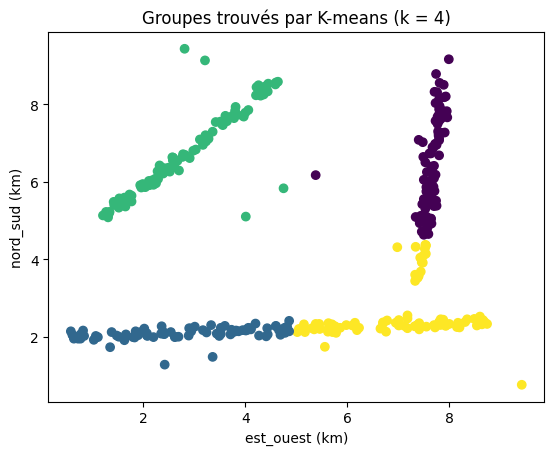

In [4]:
X = df[["est_ouest_km","nord_sud_km"]]
kmeans = KMeans(n_clusters= 4 , n_init= 10 ,random_state= 42)
kmeans.fit(X)
labels = kmeans.labels_
plt.scatter(x, y, c=labels, cmap="viridis")
plt.xlabel("est_ouest (km)")
plt.ylabel("nord_sud (km)")
plt.title("Groupes trouvés par K-means (k = 4)")
plt.show()

**Comparaison avec ce qu'on avait vu à l'œil**

Les groupes de K-means **ne correspondent pas aux axes**.

- Avec **k = 4** : l'axe horizontal est coupé en deux, le bas de l'axe vertical est mélangé avec la partie droite de l'axe horizontal, et toutes les adresses isolées sont rangées dans un groupe.
- Avec **k = 3** (le « bon » nombre) : seul l'axe en diagonale est bien reconnu. L'axe horizontal est encore coupé en deux, et sa partie droite est collée à l'axe vertical (groupe en forme de L). Les adresses isolées sont toujours dans des groupes.

Le problème ne vient donc pas du nombre de groupes choisi.

**Pourquoi (en une phrase) :** chez K-means, un cluster est l'ensemble des points plus proches d'un même centre que des autres centres, donc il fabrique des groupes compacts et ronds, alors que nos axes sont des lignes longues et fines, et il oblige chaque adresse, même isolée, à entrer dans un groupe.

## 4. Réglage de DBSCAN

### Choix de minPts

On a **2 colonnes** dans X (est-ouest et nord-sud). La règle donne **minPts = 2 × 2 = 4**, et jamais moins de 3. Comme le fichier contient des adresses isolées (du bruit), on monte d'un cran : **minPts = 5**.

On utilise la **même valeur** dans `NearestNeighbors` et dans `DBSCAN(min_samples=...)`.

### Courbe des distances au 5e voisin

Pour chaque adresse, on mesure la distance jusqu'à son 5e voisin (le point lui-même compte comme premier voisin), puis on range ces distances de la plus petite à la plus grande.

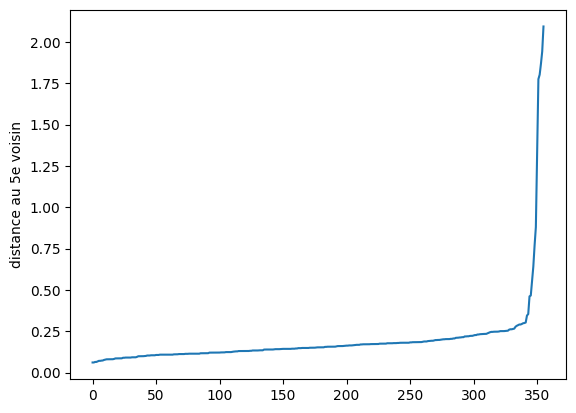

In [5]:
d = NearestNeighbors(n_neighbors= 5 ).fit(X).kneighbors(X)[0][:, -1]
plt.plot(np.sort(d))
plt.ylabel("distance au 5e voisin") 
plt.show()

**Lecture de la courbe :**
- jusqu'à environ 330 points, la courbe est basse et presque plate (0,06 à 0,25 km) : ce sont les adresses sur les axes, leurs voisins sont tout près ;
- vers 340 points, elle se plie (le coude), autour de **0,3 km** ;
- ensuite, elle monte d'un coup jusqu'à 2 km : ce sont les adresses isolées.

La courbe propose donc **ε ≈ 0,3 km** comme première idée. On le vérifie ensuite avec un balayage.

### Balayage de ε

On fait varier ε de 0,20 à 0,80 par pas de 0,05, avec `min_samples = 5`, et on regarde le nombre de clusters et d'adresses en bruit.

In [6]:
for eps in np.arange(0.20, 0.81, 0.05):
    eps = round(eps, 2)
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    nb_clusters = len(set(labels) - {-1})
    nb_bruit = (labels == -1).sum()

    print(f"eps = {eps:.2f}  |  {nb_clusters} clusters  |  {nb_bruit} bruit")

eps = 0.20  |  19 clusters  |  31 bruit
eps = 0.25  |  9 clusters  |  15 bruit
eps = 0.30  |  5 clusters  |  12 bruit
eps = 0.35  |  5 clusters  |  11 bruit
eps = 0.40  |  5 clusters  |  9 bruit
eps = 0.45  |  3 clusters  |  9 bruit
eps = 0.50  |  3 clusters  |  8 bruit
eps = 0.55  |  3 clusters  |  8 bruit
eps = 0.60  |  3 clusters  |  7 bruit
eps = 0.65  |  3 clusters  |  7 bruit
eps = 0.70  |  3 clusters  |  7 bruit
eps = 0.75  |  3 clusters  |  6 bruit
eps = 0.80  |  3 clusters  |  6 bruit


**Lecture du balayage :**
- **0,20 à 0,25** : trop petit, les axes sont découpés en morceaux (19 puis 9 clusters).
- **0,30 à 0,40** : encore trop petit, 5 clusters. Certains axes sont encore coupés (sûrement l'axe horizontal au niveau de son trou).
- **0,45 à 0,80** : **3 clusters**, stable sur toute la plage. C'est le plateau qu'on cherchait.

**Choix : ε = 0,55.** On ne prend pas 0,45, car il est au bord du plateau : à 0,40, on retombe à 5 clusters. 0,55 est au milieu : on peut le bouger un peu dans les deux sens sans que le résultat change.

**Remarque :** le coude de la courbe donnait 0,3, qui s'avère trop petit. La courbe donne une première idée, le balayage sert à la corriger.

## 5. DBSCAN avec le réglage retenu (ε = 0,55 ; min_samples = 5)

In [7]:
label = DBSCAN(eps = 0.55 , min_samples= 5 ).fit_predict(X)
nb_clusters = len(set(label) - {-1})
nb_bruit = (label == -1).sum()
print(f" {nb_clusters} clusters  |  {nb_bruit} bruit")


 3 clusters  |  8 bruit


**Combien de tournées ? Combien d'adresses isolées ?**

Avec ε = 0,55 et min_samples = 5, DBSCAN trouve **3 tournées** et **8 adresses isolées**.

Cela correspond à ce qu'on avait vu à l'œil : 3 axes, environ 6 adresses nettement isolées plus 1 ou 2 cas en limite.

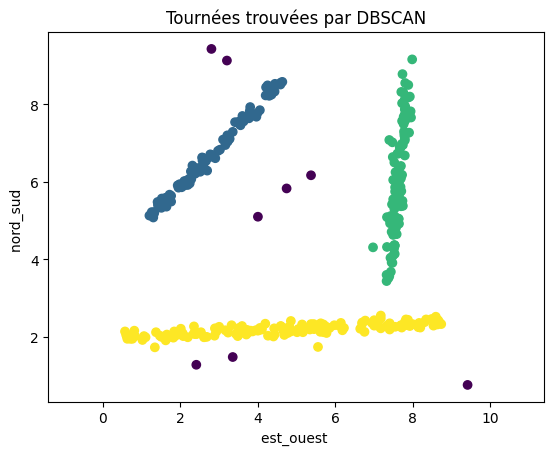

In [8]:
plt.scatter(x, y, c=label)
plt.xlabel("est_ouest ")
plt.ylabel("nord_sud ")
plt.title("Tournées trouvées par DBSCAN")
plt.axis("equal")
plt.show()

Contrairement à K-means, DBSCAN retrouve bien les **3 axes de livraison** : il suit les zones denses quelle que soit leur forme, et il laisse les adresses isolées en dehors des tournées (étiquette −1).

### Effectif de chaque tournée

In [9]:
df["cluster"] = label
print(df["cluster"].value_counts().sort_index())

cluster
-1      8
 0     92
 1    103
 2    153
Name: count, dtype: int64


| Groupe | Nombre d'adresses |
|---|---|
| −1 (adresses isolées) | 8 |
| Tournée 0 | 92 |
| Tournée 1 | 103 |
| Tournée 2 | 153 |
| **Total** | **356** |

La tournée 2 est nettement plus chargée que les autres (153 adresses). Les 8 adresses isolées devront être livrées à part.

## 6. Et si on ajoute le poids ?

### Question 16 : DBSCAN sur les deux positions + `poids_kg`, sans rien changer d'autre

In [10]:
X3 = df[["est_ouest_km", "nord_sud_km", "poids_kg"]]

labels3 = DBSCAN(eps=0.55, min_samples=5).fit_predict(X3)
print(len(set(labels3) - {-1}), "clusters,", (labels3 == -1).sum(), "bruit")

1 clusters, 351 bruit


**Résultat : 1 cluster et 351 adresses en bruit.** Les tournées ont disparu.

**Pourquoi ?** DBSCAN mélange maintenant des km et des kg dans la même distance. Le poids va de 1,5 à 39 kg, ses écarts sont beaucoup plus grands que ceux des positions. Deux maisons voisines dont les colis ont quelques kg d'écart sont considérées comme éloignées, alors que ε ne vaut que 0,55. Presque plus aucune adresse n'a assez de voisins : le poids écrase les positions.

### Question 17 : même chose, mais en standardisant les trois colonnes

In [11]:
X3_std = StandardScaler().fit_transform(X3)

labels3s = DBSCAN(eps=0.55, min_samples=5).fit_predict(X3_std)
print(len(set(labels3s) - {-1}), "clusters,", (labels3s == -1).sum(), "bruit")

2 clusters, 17 bruit


**Résultat : 2 clusters et 17 adresses en bruit.**

C'est mieux que sans standardisation, mais **moins bon qu'avec les deux positions seules** (3 tournées, 8 adresses isolées).

**Pourquoi ?** Après standardisation, le poids compte autant que chaque position. DBSCAN regroupe alors les adresses **proches et avec des colis de poids proche**. Deux maisons voisines peuvent être séparées juste parce que leurs colis n'ont pas le même poids. En plus, la standardisation déforme la carte : 1 km ne vaut plus la même chose partout.

## 7. Conclusion

### Question 18

**Fallait-il standardiser les deux positions seules ?** Non : elles sont dans la même unité (km), donc la distance calculée était déjà la vraie distance sur le terrain, et standardiser l'aurait déformée.

**Le poids a-t-il sa place dans une distance qui sert à construire des tournées ?** Non : une tournée regroupe des adresses proches les unes des autres pour que le livreur fasse le moins de trajet possible, et le poids des colis ne change rien à l'endroit où se trouvent les maisons.

**À retenir :** avant de standardiser, il faut d'abord se demander quelles colonnes ont vraiment leur place dans le calcul de distance.